# 05 · 固定检测参数下的三种 epoch 处理策略

正式滤波、眨眼检测参数和输入数据固定，在 12 份已处理的训练 EDF 上比较：

1. **faults_only**：保留眨眼相关 epoch，只排除明确故障和共同的技术有效性条件。
2. **ptp_250uv**：在同一基础上，任一 EEG 通道 PTP>250µV 时拒绝；150µV 作为敏感性对照。
3. **blink_overlap**：在同一基础上，拒绝与 CANDIDATE_blink 有任意样本重叠的 epoch。

这是处理策略的模拟：所有事件、16 通道指标、拒绝原因、触发通道和时序都保留，不删除数据。保留与否不使用标签，本步不训练分类器。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/three_policy_comparison.json').exists())
OUT=ROOT/'outputs/three_policy_comparison'
config=json.loads((OUT/'config_snapshot.json').read_text())
record=json.loads((OUT/'comparison_record.json').read_text())
manifest=pd.read_csv(OUT/'input_manifest.csv')
overall=pd.read_csv(OUT/'overall_summary.csv')
events=pd.read_csv(OUT/'all_epoch_policy_decisions.csv',keep_default_na=False)
PRIMARY=['faults_only','ptp_250uv','blink_overlap']
display(pd.Series(record,name='comparison record').to_frame())

,comparison record
files,12
total_events,9054
detector_parameters_unchanged,True
detector_config_sha256,eccd8412f204e3270627898baa729d2a9154051f32e503...
original_manifest_unchanged,True
base_faults,"[incomplete, filter_startup, nonfinite, filter..."
jump_flat_candidates,report only; not confirmed faults
baseline,None
ptp_primary_upper_uv,250.0
simulation_only,True


## 1. 共用的基础条件

三种策略都排除：不完整窗口、滤波启动期、原始或滤波后的非有限值、非有限值之后的滤波恢复区，以及达到持续时间条件（0.25 秒）的原始恒定或全零片段。恒定/全零标记在 epoch 判定时已经可知。

跳变和低变化候选、持续异常通道只作标记，不作为排除条件；不做重参考或插值。faults_only 没有 PTP 上下限。近乎平线的原始片段保存下来供复核，只有精确恒定或全零按上述规则排除。

每份 EDF 单独初始化并连续因果处理，epoch 为 [onset, onset+ceil(0.8×fs))，baseline=None。三种策略使用同一批 epoch，差异只来自 PTP 上限或眨眼重叠条件。

In [2]:
display(pd.Series(config,name='fixed comparison settings').to_frame())
display(pd.Series(json.loads((OUT/'detector_config_snapshot.json').read_text()),name='unchanged blink detector').to_frame())
reasons=pd.read_csv(OUT/'rejection_reasons.csv')
display(reasons[reasons.strategy.eq('faults_only')])

,fixed comparison settings
status,fixed-parameter simulated policy comparison; n...
source_config,configs/expanded_pilot.json
source_manifest,outputs/blink_annotation_update/all_processed_...
qc_channels,"[EEG_F3, EEG_Fz, EEG_F4, EEG_T7, EEG_C3, EEG_C..."
hard_faults,"[incomplete, filter_startup, nonfinite, filter..."
report_only,"[CANDIDATE_jump, CANDIDATE_flat, persistent_ch..."
ptp_primary_upper_uv,250.0
ptp_sensitivity_upper_uv,[150.0]
ptp_lower_rejection,None
blink_overlap_rule,any positive sample overlap with existing CAND...


,unchanged blink detector
status,unvalidated engineering candidates; fixed para...
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"
posterior_channels,"[EEG_Pz, EEG_PO7, EEG_PO8, EEG_Oz]"
auxiliary_lowpass_hz,5.0
auxiliary_order,2
entry_uv,20.0
exit_uv,10.0
min_frontal_amplitude_uv,25.0
min_support_channels,2
support_peak_fraction,0.5


,strategy,edf_name,reason,count
21,faults_only,F_03_SE001_CBCol_Train01.edf,filter_startup,22
22,faults_only,F_03_SE002_CBCol_Train01.edf,filter_startup,22
23,faults_only,F_05_SE001_CBCol_Train02.edf,filter_startup,22
24,faults_only,F_05_SE002_CBCol_Train01.edf,filter_startup,22
25,faults_only,F_05_SE002_CBCol_Train02.edf,filter_startup,22
26,faults_only,F_05_SE003_CBCol_Train04.edf,filter_startup,22
27,faults_only,F_06_SE001_CBCol_Train01.edf,filter_startup,22
28,faults_only,F_06_SE002_CBCol_Train01.edf,filter_startup,22
29,faults_only,F_08_SE003_CBCol_Train03.edf,filter_startup,22
30,faults_only,F_20_SE001_CBCol_Train01.edf,filter_startup,22


## 2. 数据范围

8 份文件按预定规则选出；另外 4 份因有人工标注而补充处理。全部为训练数据。统计按 cohort 分层，站点为推断值。

In [3]:
display(manifest.reset_index(names='zero_based_index'))
display(pd.read_csv(OUT/'cohort_summary.csv'))

,zero_based_index,edf_name,results_path,source_record_sha256,epoch_table_sha256,blink_links_sha256,subject_id,session_id,site,in_frozen_pilot
0,0,F_03_SE001_CBCol_Train01.edf,outputs\expanded_pilot\F_03_SE001_CBCol_Train01,349fce2db4dadcb8a90dbc070fd105b49672f896b44199...,0a1682b2f6602d2ee9f1a5adb934d892208e3af1f22d28...,5eff17ee9b9a074a0657cf4ae3ec13c17d9e60fb1ea442...,F_03,SE001,ETSU,True
1,1,F_03_SE002_CBCol_Train01.edf,outputs\expanded_pilot\F_03_SE002_CBCol_Train01,97f75bce9a91d1142057fa8bfc53adff83eff0aad706d9...,8fefe0705409619793a48be1e2f7fcf3fd2ea3328027fb...,6ab9f5bac29cd38457fd142f43a2bfcddfdfe12ab806da...,F_03,SE002,ETSU,True
2,2,F_05_SE001_CBCol_Train02.edf,outputs\expanded_pilot\F_05_SE001_CBCol_Train02,eef05427c6cc69a967377643bd207041573c3b3b052c70...,70ea2ce06265e201a47ab46079216bd13e7c81a7423f20...,f111e227b4d98cb0e00504a0c1dcbf29045e2cc8ec76c4...,F_05,SE001,Duke,True
3,3,F_05_SE002_CBCol_Train01.edf,outputs\expanded_pilot\F_05_SE002_CBCol_Train01,4453d6721ef696af0970c039e2e220e4b542afeb28b57a...,b422ddbc1071f5a3fa468ae09f1263255fc74df168e35c...,da73a0fd16d2c6146077443e9d299a8fda113f0a00e243...,F_05,SE002,Duke,True
4,4,F_06_SE001_CBCol_Train01.edf,outputs\expanded_pilot\F_06_SE001_CBCol_Train01,fe8a6f43d1e80855798af7ee1d9139d75838f0d2c58e78...,0591c5195639df4651e4750f042ad246dfbe00296d9d28...,5eff17ee9b9a074a0657cf4ae3ec13c17d9e60fb1ea442...,F_06,SE001,Duke,True
5,5,F_06_SE002_CBCol_Train01.edf,outputs\expanded_pilot\F_06_SE002_CBCol_Train01,f2bca4332e85dee9dfa6dae213230bfc8ed34a8cb664d2...,5d279583cb988bee85856dd9c9142eaa7d0b1aa0abde7e...,5eff17ee9b9a074a0657cf4ae3ec13c17d9e60fb1ea442...,F_06,SE002,Duke,True
6,6,F_20_SE001_CBCol_Train01.edf,outputs\expanded_pilot\F_20_SE001_CBCol_Train01,87ce5fff4c7bf9fe46d631c806f04292f366f98645275b...,ca6c9455133225e4ffca5f25ad966c7376cf7269206821...,93bd5564d1e1ba5a7bf147732d63bdb64ce11d726212cb...,F_20,SE001,ETSU,True
7,7,F_20_SE002_CBCol_Train01.edf,outputs\expanded_pilot\F_20_SE002_CBCol_Train01,029220d56530069486a555ee6475b1ff9468c968d6b829...,fa1191f64803689288e523d69b2f0804e90528fdeabe41...,ae954ccfa578798a01391def358b74245113ec8764abab...,F_20,SE002,ETSU,True
8,8,F_05_SE002_CBCol_Train02.edf,outputs\blink_annotation_update\additional_edf...,946a93c64604de56de075658a16f84c54817fe0df10fcc...,2ae9264a7cd3d57d75e64292012c17f0dc34abb3e0b708...,04a7829e2f88aae7e44eece6cc79629a4870d2d2e861f6...,F_05,SE002,Duke,False
9,9,F_05_SE003_CBCol_Train04.edf,outputs\blink_annotation_update\additional_edf...,e557905f92667a40679bc8e767910066f042f209de8404...,3e60e05794d2a32a4f71d3b1c0545ea1fe0f38e8e1a2da...,c18c9378cd463b0748595c70161d7259ccd7010c3683d4...,F_05,SE003,Duke,False


,strategy,in_frozen_pilot,total_flashes,expected_kept,expected_retention,common_fault_epochs,pending_at_eof,mean_extra_wait_seconds
0,blink_overlap,False,3024,1599,0.528770,88,0,1.355469
1,blink_overlap,True,6030,5086,0.843449,176,0,1.355469
2,faults_only,False,3024,2936,0.970899,88,0,0.000000
3,faults_only,True,6030,5854,0.970813,176,0,0.000000
4,ptp_150uv_sensitivity,False,3024,2652,0.876984,88,0,0.000000
5,ptp_150uv_sensitivity,True,6030,5735,0.951078,176,0,0.000000
6,ptp_250uv,False,3024,2936,0.970899,88,0,0.000000
7,ptp_250uv,True,6030,5854,0.970813,176,0,0.000000


## 3. 保留率与额外拒绝

共同排除 264 个 epoch，全部来自各 EDF 前 10 秒的启动保护。这批数据中没有非有限、精确恒定或全零等额外故障。

250µV 方案与基础方案结果相同：通过基础条件的 epoch 都没有超过该上限。150µV 是更严格的敏感性方案。眨眼重叠策略额外拒绝了大量 epoch。

In [4]:
display(overall)
base=int(overall.loc[overall.strategy.eq('faults_only'),'expected_kept'].iloc[0])
comparison=overall.copy()
comparison['extra_rejected_vs_faults_only']=base-comparison.expected_kept
comparison['extra_rejected_fraction_of_base_usable']=(base-comparison.expected_kept)/base
display(comparison[['strategy','expected_kept','expected_retention','extra_rejected_vs_faults_only','extra_rejected_fraction_of_base_usable']])
display(pd.read_csv(OUT/'additional_rejection_overlap.csv'))

,strategy,total_flashes,expected_kept,expected_retention,common_fault_epochs,pending_at_eof,mean_extra_wait_seconds
0,blink_overlap,9054,6685,0.738348,264,0,1.355469
1,faults_only,9054,8790,0.970842,264,0,0.000000
2,ptp_150uv_sensitivity,9054,8387,0.926331,264,0,0.000000
3,ptp_250uv,9054,8790,0.970842,264,0,0.000000


,strategy,expected_kept,expected_retention,extra_rejected_vs_faults_only,extra_rejected_fraction_of_base_usable
0,blink_overlap,6685,0.738348,2105,0.239477
1,faults_only,8790,0.970842,0,0.000000
2,ptp_150uv_sensitivity,8387,0.926331,403,0.045848
3,ptp_250uv,8790,0.970842,0,0.000000


,category,epochs
0,both,0
1,ptp_only,0
2,blink_only,2105
3,neither,6685


## 4. 各文件与被试、Session 的差异

文件按 manifest 编号 1–12。候选较多的被试会主导合并保留率，所以同时给出逐文件结果和实际拒绝集合。

strategy,blink_overlap,faults_only,ptp_150uv_sensitivity,ptp_250uv
edf_name,,,,
F_03_SE001_CBCol_Train01.edf,734,734,734,734
F_03_SE002_CBCol_Train01.edf,723,734,734,734
F_05_SE001_CBCol_Train02.edf,405,734,729,734
F_05_SE002_CBCol_Train01.edf,328,734,629,734
F_05_SE002_CBCol_Train02.edf,234,734,501,734
F_05_SE003_CBCol_Train04.edf,238,734,731,734
F_06_SE001_CBCol_Train01.edf,734,734,725,734
F_06_SE002_CBCol_Train01.edf,734,734,734,734
F_08_SE003_CBCol_Train03.edf,623,734,689,734


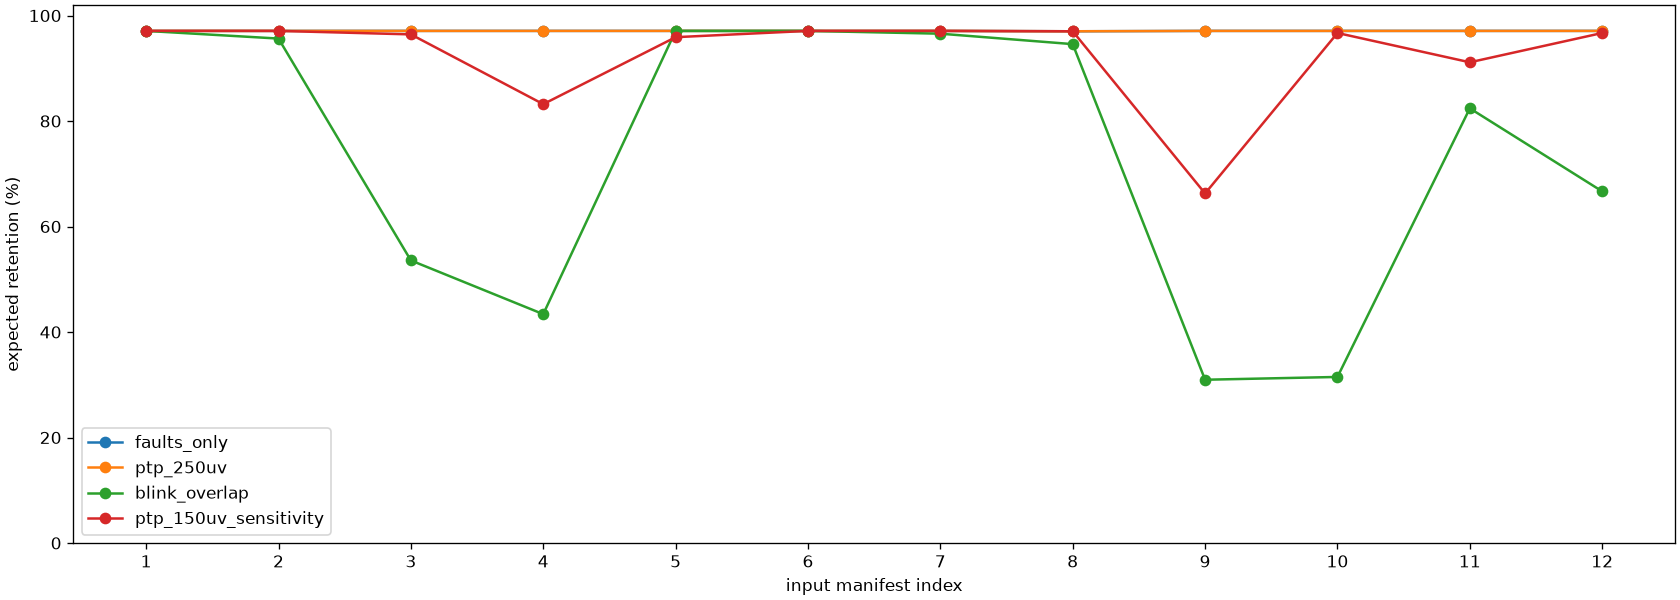

,strategy,subject_id,total_flashes,expected_kept,expected_retention,common_fault_epochs,pending_at_eof,mean_extra_wait_seconds
0,blink_overlap,F_03,1512,1457,0.963624,44,0,1.355469
1,blink_overlap,F_05,3024,1205,0.398479,88,0,1.355469
2,blink_overlap,F_06,1512,1468,0.970899,44,0,1.355469
3,blink_overlap,F_08,756,623,0.824074,22,0,1.355469
4,blink_overlap,F_20,1494,1428,0.955823,44,0,1.355469
5,blink_overlap,F_25,756,504,0.666667,22,0,1.355469
6,faults_only,F_03,1512,1468,0.970899,44,0,0.000000
7,faults_only,F_05,3024,2936,0.970899,88,0,0.000000
8,faults_only,F_06,1512,1468,0.970899,44,0,0.000000
9,faults_only,F_08,756,734,0.970899,22,0,0.000000


In [5]:
s=pd.read_csv(OUT/'edf_summary.csv')
display(s.pivot(index='edf_name',columns='strategy',values='expected_kept'))
display(Image(filename=str(OUT/'retention_by_file.png'),width=1250))
display(pd.read_csv(OUT/'subject_summary.csv'))

## 5. target 与 non-target 的保留率

标签只用于这里的事后分组。分类效果在后续 SWLDA 实验（notebook 06）中按验证划分评估。

In [6]:
label=events.groupby(['strategy','label']).agg(total=('would_keep','size'),kept=('would_keep','sum'),retention=('would_keep','mean')).reset_index()
display(label)

,strategy,label,total,kept,retention
0,blink_overlap,non-target,8048,6035,0.749876
1,blink_overlap,target,1006,650,0.646123
2,faults_only,non-target,8048,7812,0.970676
3,faults_only,target,1006,978,0.972167
4,ptp_150uv_sensitivity,non-target,8048,7509,0.933027
5,ptp_150uv_sensitivity,target,1006,878,0.872763
6,ptp_250uv,non-target,8048,7812,0.970676
7,ptp_250uv,target,1006,978,0.972167


## 6. 每个字符和刺激集合的剩余 flash 数

拒绝以 epoch 为单位，字符整体保留。下面给出每种策略下每字符可用 flash 数的范围，并以 F_05 SE003 Train04 为例。本步不设最小证据量和动态停止规则。

stimulus_group_id 是实际同时亮起的字符集合签名，原始 StimulusCode 同时保留；很多集合只出现一次。

In [7]:
characters=pd.read_csv(OUT/'character_summary.csv')
display(characters.groupby('strategy').expected_kept.agg(['count','min','median','max']))
display(characters[characters.edf_name.eq('F_05_SE003_CBCol_Train04.edf')])
groups=pd.read_csv(OUT/'stimulus_group_summary.csv')
display(groups[groups.edf_name.eq('F_05_SE003_CBCol_Train04.edf') & groups.strategy.eq('blink_overlap')].head(15))
print('全部逐刺激集合计数：',(OUT/'stimulus_group_summary.csv').relative_to(ROOT).as_posix())

,count,min,median,max
strategy,,,,
blink_overlap,72,19,104.0,126
faults_only,72,86,126.0,126
ptp_150uv_sensitivity,72,58,126.0,126
ptp_250uv,72,86,126.0,126


,strategy,edf_name,character_trial_id,total_flashes,expected_kept,expected_retention,common_fault_epochs,pending_at_eof,mean_extra_wait_seconds
30,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,126,41,0.325397,22,0,1.355469
31,blink_overlap,F_05_SE003_CBCol_Train04.edf,2,126,41,0.325397,0,0,1.355469
32,blink_overlap,F_05_SE003_CBCol_Train04.edf,3,126,53,0.420635,0,0,1.355469
33,blink_overlap,F_05_SE003_CBCol_Train04.edf,4,126,33,0.261905,0,0,1.355469
34,blink_overlap,F_05_SE003_CBCol_Train04.edf,5,126,32,0.253968,0,0,1.355469
35,blink_overlap,F_05_SE003_CBCol_Train04.edf,6,126,38,0.301587,0,0,1.355469
102,faults_only,F_05_SE003_CBCol_Train04.edf,1,126,104,0.825397,22,0,0.000000
103,faults_only,F_05_SE003_CBCol_Train04.edf,2,126,126,1.000000,0,0,0.000000
104,faults_only,F_05_SE003_CBCol_Train04.edf,3,126,126,1.000000,0,0,0.000000
105,faults_only,F_05_SE003_CBCol_Train04.edf,4,126,126,1.000000,0,0,0.000000


,strategy,edf_name,character_trial_id,stimulus_group_id,total_flashes,expected_kept,expected_retention,common_fault_epochs,pending_at_eof,mean_extra_wait_seconds
3760,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_02586c7d18ad,1,0,0.0,0,0,1.355469
3761,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_04d0b3213e70,1,0,0.0,0,0,1.355469
3762,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_059cb8e126cf,1,0,0.0,0,0,1.355469
3763,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_0b2959d0085f,1,1,1.0,0,0,1.355469
3764,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_0d4492df04ae,1,1,1.0,0,0,1.355469
3765,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_0e0947bc8c58,1,0,0.0,1,0,1.355469
3766,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_0eb4d98601c3,1,1,1.0,0,0,1.355469
3767,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_0ef2f6612182,1,1,1.0,0,0,1.355469
3768,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_108d81f028c0,1,0,0.0,0,0,1.355469
3769,blink_overlap,F_05_SE003_CBCol_Train04.edf,1,observed_14adae2da54d,1,0,0.0,0,0,1.355469


全部逐刺激集合计数： outputs/three_policy_comparison/stimulus_group_summary.csv


## 7. 触发通道与拒绝原因

PTP 拒绝记录实际超过上限的通道，基础故障记录故障通道。眨眼重叠按事件关联记录，触发通道可在候选表的 supporting_channels 中查到。

In [8]:
triggers=pd.read_csv(OUT/'trigger_channels.csv')
display(triggers.groupby(['strategy','channel'])['count'].sum().sort_values(ascending=False).to_frame())
display(pd.read_csv(OUT/'rejection_reasons.csv').groupby(['strategy','reason'])['count'].sum().to_frame())

count
strategy              channel       
ptp_150uv_sensitivity EEG_F3     380
                      EEG_F4     244
                      EEG_Fz      72
                      EEG_T7      12
                      EEG_Pz       3

count
strategy              reason                        
blink_overlap         blink_candidate_overlap   2150
                      filter_startup             264
faults_only           filter_startup             264
ptp_150uv_sensitivity filter_startup             264
                      ptp_high                   413
ptp_250uv             filter_startup             264

## 8. 两段完整人工复核区间内的保留情况

只看完全落在人工复核区间内、且通过共同基础条件的 epoch：F_05 SE003 Train04 的 0–35 秒、F_08 SE003 Train03 的 1–50 秒。与人工眨眼是否相交作为描述性标签，不参与策略判定。

自动候选区间常比人工边界更长：辅助因果分支有延迟，并包含眨眼的恢复尾波。因此会出现“与人工眨眼不相交、但被眨眼策略拒绝”的 epoch；反过来，与人工边界相交的 epoch 也不一定全部被拒绝。

In [9]:
review=pd.read_csv(OUT/'reviewed_epoch_summary.csv')
display(review)
print('overlaps_manual_blink=True：epoch与人工疑似眨眼时间段相交；False：完整检查区间内未相交。')

,edf_name,strategy,overlaps_manual_blink,total,kept,rejected
0,F_05_SE003_CBCol_Train04.edf,blink_overlap,False,44,29,15
1,F_05_SE003_CBCol_Train04.edf,blink_overlap,True,53,6,47
2,F_05_SE003_CBCol_Train04.edf,faults_only,False,44,44,0
3,F_05_SE003_CBCol_Train04.edf,faults_only,True,53,53,0
4,F_05_SE003_CBCol_Train04.edf,ptp_150uv_sensitivity,False,44,44,0
5,F_05_SE003_CBCol_Train04.edf,ptp_150uv_sensitivity,True,53,53,0
6,F_05_SE003_CBCol_Train04.edf,ptp_250uv,False,44,44,0
7,F_05_SE003_CBCol_Train04.edf,ptp_250uv,True,53,53,0
8,F_08_SE003_CBCol_Train03.edf,blink_overlap,False,129,126,3
9,F_08_SE003_CBCol_Train03.edf,blink_overlap,True,14,2,12


overlaps_manual_blink=True：epoch与人工疑似眨眼时间段相交；False：完整检查区间内未相交。


## 9. 在线判定时间

基础和 PTP 方案在 0–800 ms 样本到齐后即可判定。眨眼候选需要等待恢复与合并，所以眨眼策略使用统一的确认窗口：epoch 样本终点 + 最大候选持续时间 1.2 秒 + max(恢复 0.08 秒, 合并 0.15 秒)，各项按整数样本向上取整；在 256 Hz 下额外等待约 1.355 秒。

would_keep 是策略结果，policy_decision_seconds 是判定时刻。文件末尾数据不足时标记为 pending_at_eof；本批 epoch 的 pending 数为 0。

In [10]:
display(overall[['strategy','mean_extra_wait_seconds','pending_at_eof']])
display(events.loc[events.strategy.eq('blink_overlap'),['edf_name','event_index','epoch_decision_seconds','policy_decision_seconds','additional_wait_seconds','decision_data_available']].head(8))

,strategy,mean_extra_wait_seconds,pending_at_eof
0,blink_overlap,1.355469,0
1,faults_only,0.000000,0
2,ptp_150uv_sensitivity,0.000000,0
3,ptp_250uv,0.000000,0


,edf_name,event_index,epoch_decision_seconds,policy_decision_seconds,additional_wait_seconds,decision_data_available
2,F_03_SE001_CBCol_Train01.edf,0,5.300781,6.65625,1.355469,True
6,F_03_SE001_CBCol_Train01.edf,1,5.550781,6.90625,1.355469,True
10,F_03_SE001_CBCol_Train01.edf,2,5.800781,7.15625,1.355469,True
14,F_03_SE001_CBCol_Train01.edf,3,6.050781,7.40625,1.355469,True
18,F_03_SE001_CBCol_Train01.edf,4,6.300781,7.65625,1.355469,True
22,F_03_SE001_CBCol_Train01.edf,5,6.550781,7.90625,1.355469,True
26,F_03_SE001_CBCol_Train01.edf,6,6.800781,8.15625,1.355469,True
30,F_03_SE001_CBCol_Train01.edf,7,7.050781,8.40625,1.355469,True


## 10. 三种处理后的平均 ERP

同一正式因果信号，baseline=None，平均各方案保留的完整有限 epoch。每条曲线标出参与平均的数量，各通道和类别共享坐标。曲线按 epoch 合并 12 份 EDF，被试构成和类别数会影响形态。250µV 与基础方案的曲线重合，因为本批没有额外拒绝。

,strategy,label,n_epochs
0,faults_only,target,978
1,faults_only,non-target,7812
2,ptp_250uv,target,978
3,ptp_250uv,non-target,7812
4,blink_overlap,target,650
5,blink_overlap,non-target,6035
6,ptp_150uv_sensitivity,target,878
7,ptp_150uv_sensitivity,non-target,7509


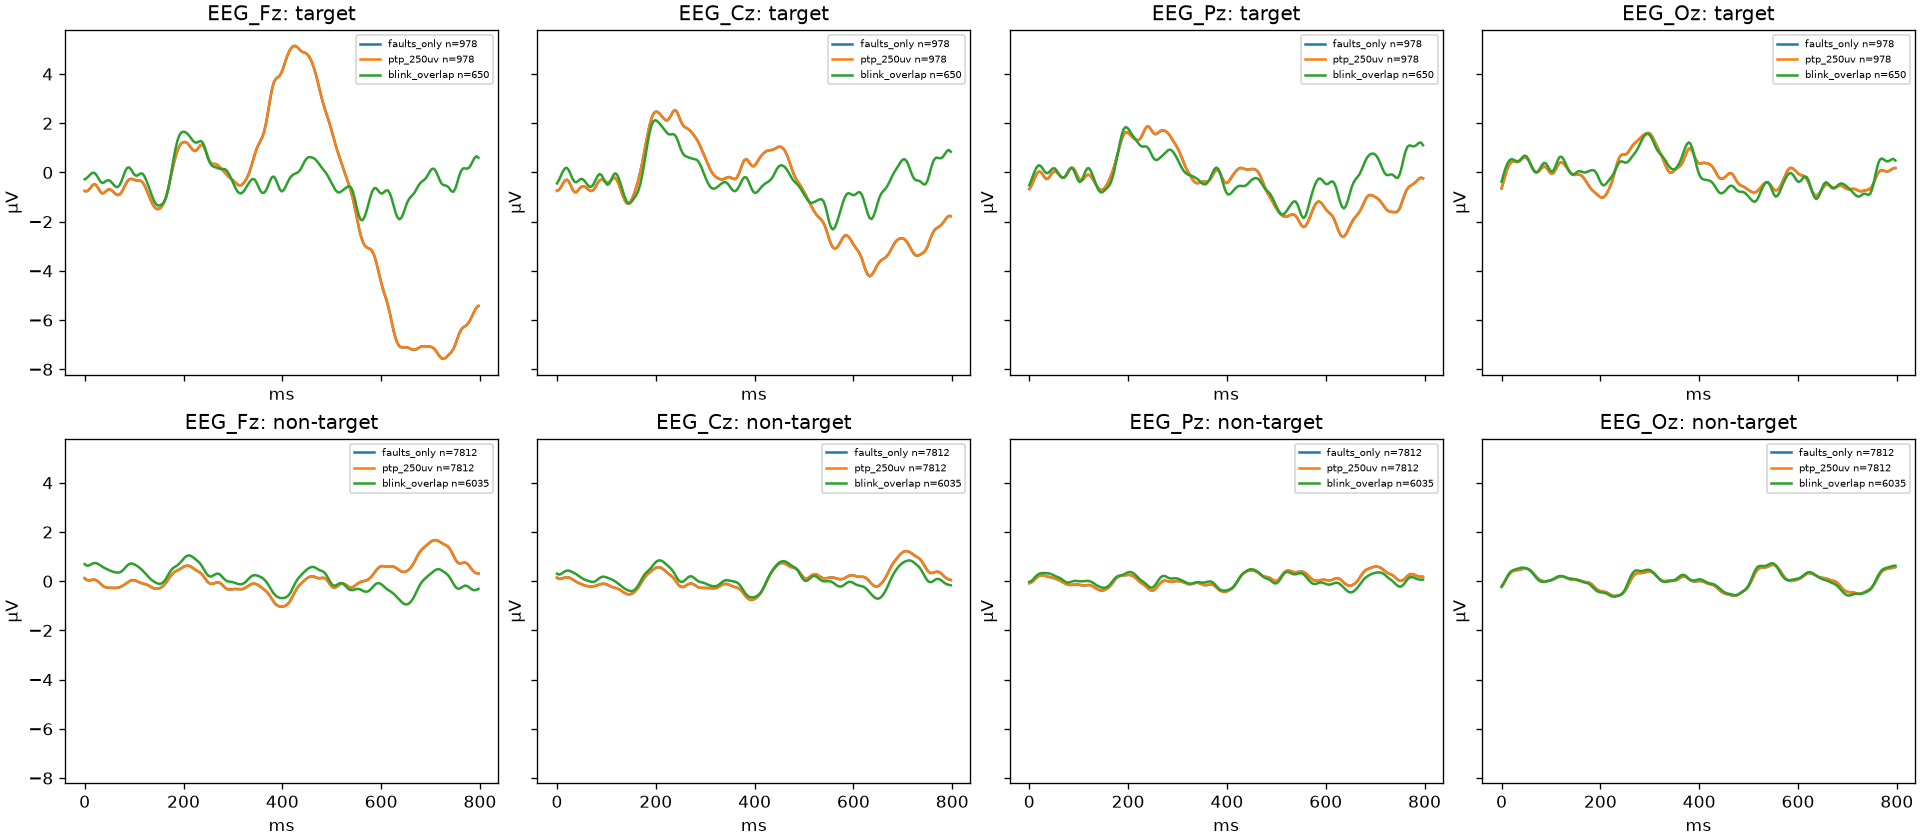

In [11]:
display(pd.read_csv(OUT/'pooled_erp_counts.csv'))
display(Image(filename=str(OUT/'pooled_erp.png'),width=1300))

## 11. 一致性检查与复现

运行：`python scripts/compare_epoch_policies.py`；配置：`configs/three_policy_comparison.json`。运行时检查眨眼检测参数哈希和原 8 文件清单。

结果包含全部 9,054 个 epoch × 每种方案。被拒绝的 flash 在后续分类中不给分数。13 项回归测试覆盖故障条件、标签不参与、策略差异、等待时间与文件末尾等行为；下面检查保存结果的一致性。

In [12]:
assert record['detector_parameters_unchanged'] and record['actual_epochs_removed']==0
counts=events.groupby('strategy').size()
assert counts.eq(record['total_events']).all()
wide=events.pivot(index=['edf_name','event_index'],columns='strategy',values='would_keep')
for strategy in wide:
    assert (wide[strategy]<=wide.faults_only).all()
assert (events.onset_sample==events.original_event_sample).all()
assert events.groupby(['edf_name','event_index']).common_fault.nunique().eq(1).all()
assert events.loc[events.strategy.eq('blink_overlap'),'additional_wait_seconds'].gt(0).all()
assert events.loc[events.strategy.eq('faults_only'),'additional_wait_seconds'].eq(0).all()
print('PASS: all events preserved, common baseline identical, criteria nested, event samples unchanged, confirmation wait explicit')

PASS: all events preserved, common baseline identical, criteria nested, event samples unchanged, confirmation wait explicit
